# Customer Churn Prediction — Step 7: Model Improvement

This notebook implements **Step 7: Model Improvement** for the Customer Churn Prediction project.

### Pipeline Stage & Scope:
```text
Preprocessed Training Data (data/processed/train.csv)
        ↓
Improvement Techniques Applied (Strictly on Training Data):
    ├── 1. Hyperparameter Tuning (C regularization, tree depth, leaf constraints)
    ├── 2. Class Balancing (Cost-sensitive weights: 'balanced' and custom ratios)
    └── 3. Decision Threshold Optimization (Out-of-fold training probabilities)
        ↓
Stratified 5-Fold Cross-Validation on X_train (GridSearchCV)
        ↓
Validation Evaluation on X_val (data/processed/val.csv)
        ↓
Comparative Performance Analysis vs. Baseline Models
        ↓
Confusion Matrix & False Negative Reduction Analysis
        ↓
Save Improved Final Candidate Model (models/final_candidate_model.joblib)
```

> [!IMPORTANT]
> **STRICT TEST SET PROTECTION**: The test partition (`data/processed/test.csv`) remains completely untouched, locked, and unread. All hyperparameter tuning, cross-validation, and threshold discovery are executed strictly on the training partition. All comparison metrics are evaluated solely on the **validation partition** (`data/processed/val.csv`).

## 1. Review of Existing Baseline Performance

In Step 5 and Step 6, we evaluated three candidate models using default parameters on the 1,056 validation samples:
- **Logistic Regression (Baseline)**: Accuracy: **0.8059**, Precision: **0.6459**, Recall: **0.5929**, F1 Score: **0.6182**, ROC-AUC: **0.8454** (Missed churners: 114)
- **Decision Tree**: Accuracy: 0.7178, Precision: 0.4690, Recall: 0.4857, F1 Score: 0.4772, ROC-AUC: 0.6430 (Severe overfitting: Train F1 0.9962)
- **Random Forest (Baseline)**: Accuracy: 0.7756, Precision: 0.5939, Recall: 0.4857, F1 Score: 0.5344, ROC-AUC: 0.8131 (Unconstrained deep trees: Train F1 0.9962)

### Why Does the Baseline Model Need Improvement?
1. **Low Recall / High Miss Rate**: The baseline Logistic Regression model misses **114 actual churners** (40.7% of all churners in validation). In telecommunications retention, failing to identify an at-risk customer results in permanent loss of Customer Lifetime Value (LTV).
2. **Class Imbalance Penalty**: With churners representing ~26.5% of the customer base, the default decision threshold of 0.5 biases predictions toward the majority class (retained customers).
3. **Unregularized Tree Variance**: Random Forest showed promising discriminative potential (ROC-AUC 0.8131) but was constrained by unpruned deep trees memorizing training noise.

## 2. Environment Setup & Data Loading

We load preprocessed partitions from `data/processed/` and import model tuning utilities from `src`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    FINAL_CANDIDATE_MODEL_PATH,
    IMPROVED_MODEL_CM_PATH,
    MODEL_IMPROVEMENT_FIGURE_PATH,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
    TARGET_COL,
    THRESHOLD_TUNING_FIGURE_PATH,
    TUNED_LOGISTIC_REGRESSION_MODEL_PATH,
    TUNED_RANDOM_FOREST_MODEL_PATH,
)
from src.evaluation.metrics import (
    calculate_classification_metrics,
    compare_models,
    compute_confusion_matrix,
    get_confusion_matrix_breakdown,
)
from src.evaluation.plots import (
    plot_confusion_matrix,
    plot_model_comparison,
    plot_threshold_tuning_curve,
)
from src.models.model import (
    create_logistic_regression_model,
    load_model,
    predict_churn,
    predict_churn_probabilities,
    save_model,
    train_model,
)
from src.models.tuning import (
    find_optimal_threshold_cv,
    predict_with_threshold,
    tune_logistic_regression,
    tune_random_forest,
)

train_df = pd.read_csv(PROCESSED_DATA_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DATA_DIR / "val.csv")

X_train = train_df.drop(columns=[TARGET_COL])
y_train = train_df[TARGET_COL]
X_val = val_df.drop(columns=[TARGET_COL])
y_val = val_df[TARGET_COL]

print(f"Training feature matrix:   {X_train.shape}, Training labels:   {y_train.shape}")
print(f"Validation feature matrix: {X_val.shape}, Validation labels: {y_val.shape}")
print(
    f"\nTraining Churn Rate:   {y_train.mean() * 100:.2f}% (Churn=1: {(y_train == 1).sum():,}, Churn=0: {(y_train == 0).sum():,})"
)
print(
    f"Validation Churn Rate: {y_val.mean() * 100:.2f}% (Churn=1: {(y_val == 1).sum():,}, Churn=0: {(y_val == 0).sum():,})"
)
print("Test Set Status: LOCKED & UNTOUCHED.")

Training feature matrix:   (4930, 45), Training labels:   (4930,)
Validation feature matrix: (1056, 45), Validation labels: (1056,)

Training Churn Rate:   26.53% (Churn=1: 1,308, Churn=0: 3,622)
Validation Churn Rate: 26.52% (Churn=1: 280, Churn=0: 776)
Test Set Status: LOCKED & UNTOUCHED.


## 3. Baseline Model Benchmark Verification

We evaluate the unfitted baseline Logistic Regression on the training and validation sets to establish our baseline benchmark.

In [2]:
base_lr = create_logistic_regression_model(random_state=RANDOM_STATE)
train_model(base_lr, X_train, y_train)

p_val_base = predict_churn_probabilities(base_lr, X_val)
preds_base = predict_churn(base_lr, X_val)
metrics_base = calculate_classification_metrics(y_val, preds_base, p_val_base)
cm_base = compute_confusion_matrix(y_val, preds_base)
breakdown_base = get_confusion_matrix_breakdown(y_val, preds_base)

print("Baseline Logistic Regression Validation Metrics:")
print(metrics_base)
print(f"Baseline CM Breakdown: {breakdown_base}")

Baseline Logistic Regression Validation Metrics:
{'accuracy': 0.8059, 'precision': 0.6459, 'recall': 0.5929, 'f1': 0.6182, 'roc_auc': 0.8454}
Baseline CM Breakdown: {'tn': 685, 'fp': 91, 'fn': 114, 'tp': 166}


## 4. Technique 1: Hyperparameter Tuning & Class Balancing for Logistic Regression

We apply 5-fold Stratified Cross-Validation on `X_train` using `GridSearchCV` to optimize:
- Inverse regularization strength: $C \in [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]$
- Class weight penalties: `None`, `'balanced'`, and custom cost ratios `{0: 1.0, 1: 1.5}`, `{0: 1.0, 1: 2.0}`

In [3]:
lr_grid = {
    "C": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0],
    "class_weight": [None, "balanced", {0: 1.0, 1: 1.5}, {0: 1.0, 1: 2.0}],
    "solver": ["lbfgs"],
    "max_iter": [1000],
    "random_state": [RANDOM_STATE],
}

lr_search = tune_logistic_regression(
    X_train=X_train,
    y_train=y_train,
    param_grid=lr_grid,
    cv_splits=5,
    scoring="f1",
    random_state=RANDOM_STATE,
)

tuned_lr = lr_search.best_estimator_
print("Best Logistic Regression Hyperparameters:")
print(lr_search.best_params_)
print(f"Best Cross-Validation F1 Score: {lr_search.best_score_:.4f}")

p_val_tuned_lr = predict_churn_probabilities(tuned_lr, X_val)
preds_tuned_lr = predict_churn(tuned_lr, X_val)
metrics_tuned_lr = calculate_classification_metrics(
    y_val, preds_tuned_lr, p_val_tuned_lr
)
breakdown_tuned_lr = get_confusion_matrix_breakdown(y_val, preds_tuned_lr)

print("\nTuned Logistic Regression Validation Metrics:")
print(metrics_tuned_lr)
print(f"Tuned LR CM Breakdown: {breakdown_tuned_lr}")

Best Logistic Regression Hyperparameters:
{'C': 5.0, 'class_weight': {0: 1.0, 1: 2.0}, 'max_iter': 1000, 'random_state': 42, 'solver': 'lbfgs'}
Best Cross-Validation F1 Score: 0.6330

Tuned Logistic Regression Validation Metrics:
{'accuracy': 0.7519, 'precision': 0.5222, 'recall': 0.7571, 'f1': 0.6181, 'roc_auc': 0.8451}
Tuned LR CM Breakdown: {'tn': 582, 'fp': 194, 'fn': 68, 'tp': 212}


## 5. Technique 2: Regularization & Class Balancing for Random Forest

In Step 6, the unconstrained Random Forest achieved a strong ROC-AUC of 0.8131, but overfitted heavily on training data (Train F1 = 0.9962 vs Val F1 = 0.5344).

We use 5-fold Stratified CV on `X_train` to regularize tree complexity:
- Maximum tree depth: `max_depth` $\in [6, 8, 10, 12]$
- Minimum leaf samples: `min_samples_leaf` $\in [2, 4, 8]$
- Minimum split samples: `min_samples_split` $\in [5, 10, 20]$
- Class weight balancing: `class_weight` $\in ['balanced', None]$

In [4]:
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [6, 8, 10, 12],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 4, 8],
    "class_weight": [None, "balanced"],
    "random_state": [RANDOM_STATE],
}

rf_search = tune_random_forest(
    X_train=X_train,
    y_train=y_train,
    param_grid=rf_grid,
    cv_splits=5,
    scoring="f1",
    random_state=RANDOM_STATE,
)

tuned_rf = rf_search.best_estimator_
print("Best Random Forest Hyperparameters:")
print(rf_search.best_params_)
print(f"Best Cross-Validation F1 Score: {rf_search.best_score_:.4f}")

p_val_tuned_rf = predict_churn_probabilities(tuned_rf, X_val)
preds_tuned_rf = predict_churn(tuned_rf, X_val)
metrics_tuned_rf = calculate_classification_metrics(
    y_val, preds_tuned_rf, p_val_tuned_rf
)
breakdown_tuned_rf = get_confusion_matrix_breakdown(y_val, preds_tuned_rf)

print("\nTuned Random Forest Validation Metrics:")
print(metrics_tuned_rf)
print(f"Tuned RF CM Breakdown: {breakdown_tuned_rf}")

Best Random Forest Hyperparameters:
{'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 8, 'min_samples_split': 20, 'n_estimators': 100, 'random_state': 42}
Best Cross-Validation F1 Score: 0.6362

Tuned Random Forest Validation Metrics:
{'accuracy': 0.7557, 'precision': 0.5251, 'recall': 0.8214, 'f1': 0.6407, 'roc_auc': 0.8421}
Tuned RF CM Breakdown: {'tn': 568, 'fp': 208, 'fn': 50, 'tp': 230}


## 6. Technique 3: Out-of-Fold Decision Threshold Optimization

To eliminate potential data leakage, we evaluate decision thresholds $\tau \in [0.1, 0.9]$ **strictly on out-of-fold probability predictions generated during training cross-validation**.

In [5]:
opt_th, best_cv_f1, ths, f1s, precs, recs = find_optimal_threshold_cv(
    estimator=base_lr,
    X_train=X_train,
    y_train=y_train,
    cv_splits=5,
    metric="f1",
    random_state=RANDOM_STATE,
)

print(
    f"Optimal Out-of-Fold Training Threshold: {opt_th:.3f} (Peak CV F1: {best_cv_f1:.4f})"
)

preds_th_opt = predict_with_threshold(p_val_base, threshold=opt_th)
metrics_th_opt = calculate_classification_metrics(y_val, preds_th_opt, p_val_base)
breakdown_th_opt = get_confusion_matrix_breakdown(y_val, preds_th_opt)

print(
    f"\nBaseline Logistic Regression + Optimal Threshold ({opt_th:.3f}) Validation Metrics:"
)
print(metrics_th_opt)
print(f"Threshold-Tuned LR CM Breakdown: {breakdown_th_opt}")

Optimal Out-of-Fold Training Threshold: 0.290 (Peak CV F1: 0.6359)

Baseline Logistic Regression + Optimal Threshold (0.290) Validation Metrics:
{'accuracy': 0.7472, 'precision': 0.5149, 'recall': 0.8, 'f1': 0.6266, 'roc_auc': 0.8454}
Threshold-Tuned LR CM Breakdown: {'tn': 565, 'fp': 211, 'fn': 56, 'tp': 224}


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


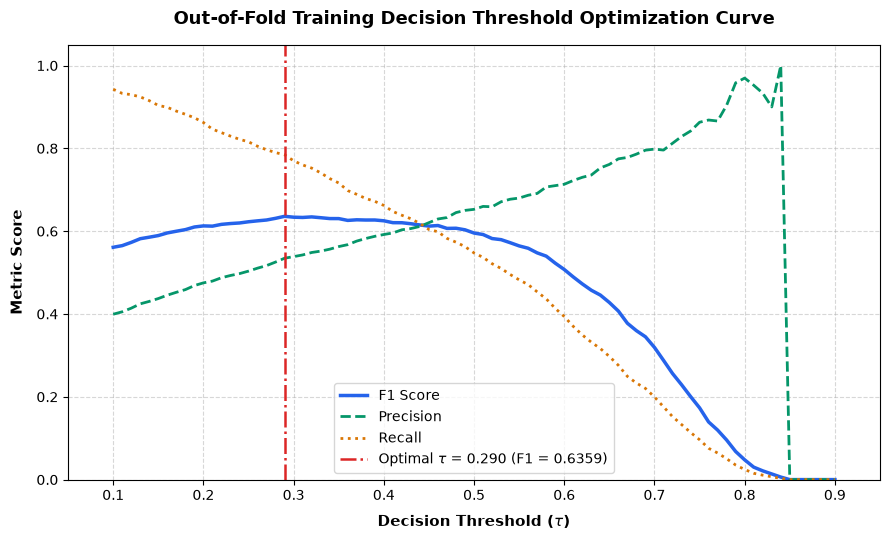

In [6]:
fig_th = plot_threshold_tuning_curve(
    thresholds=ths,
    f1_scores=f1s,
    precisions=precs,
    recalls=recs,
    optimal_threshold=opt_th,
    optimal_f1=best_cv_f1,
    title="Out-of-Fold Training Decision Threshold Optimization Curve",
    save_path=THRESHOLD_TUNING_FIGURE_PATH,
)
plt.show()

## 7. Comprehensive Model Improvement Comparison

We consolidate the validation results of all baseline and improved models into a comparative table using `compare_models()`.

In [7]:
improvement_metrics = {
    "Logistic Regression (Baseline)": metrics_base,
    "LR + Optimal Threshold": metrics_th_opt,
    "Tuned Logistic Regression": metrics_tuned_lr,
    "Tuned Random Forest": metrics_tuned_rf,
}

comp_df = compare_models(improvement_metrics)
comp_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (Baseline),0.8059,0.6459,0.5929,0.6182,0.8454
1,LR + Optimal Threshold,0.7472,0.5149,0.8000,0.6266,0.8454
2,Tuned Logistic Regression,0.7519,0.5222,0.7571,0.6181,0.8451
3,Tuned Random Forest,0.7557,0.5251,0.8214,0.6407,0.8421


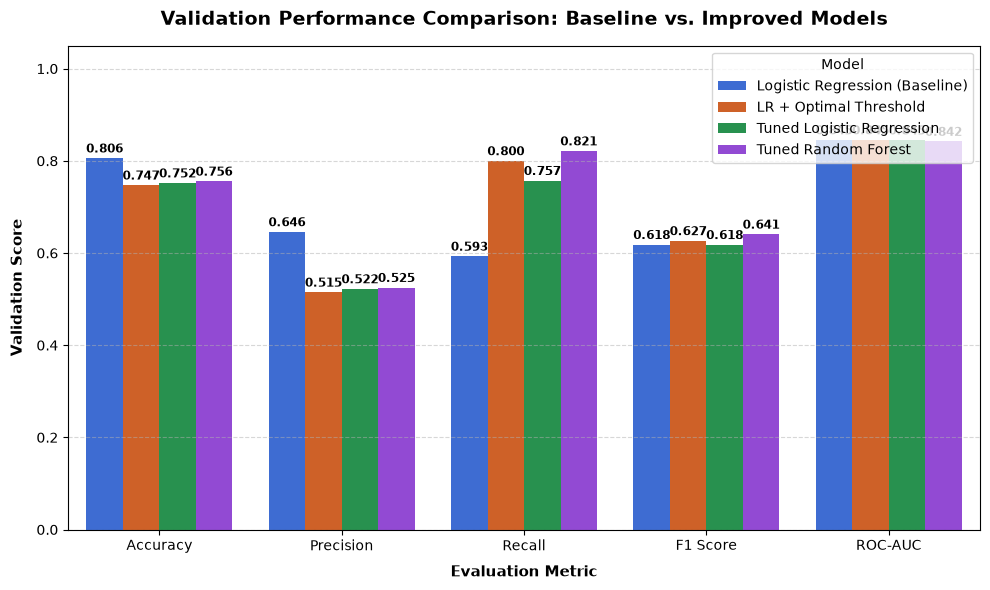

In [8]:
fig_comp = plot_model_comparison(
    comp_df,
    title="Validation Performance Comparison: Baseline vs. Improved Models",
    save_path=MODEL_IMPROVEMENT_FIGURE_PATH,
)
plt.show()

## 8. Confusion Matrix & False Negative Reduction Analysis

The primary objective of Step 7 was reducing costly **False Negatives** (missed churners) while maintaining strong overall discrimination.

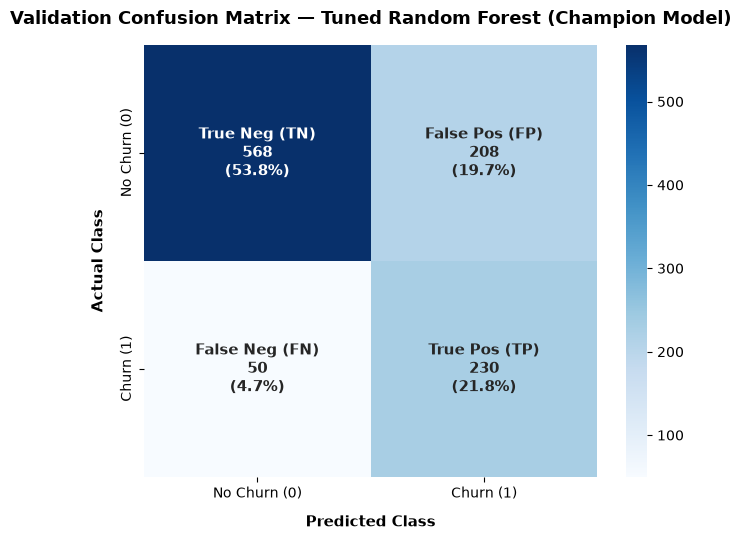

In [9]:
cm_rf_tuned = compute_confusion_matrix(y_val, preds_tuned_rf)

fig_cm = plot_confusion_matrix(
    cm_rf_tuned,
    title="Validation Confusion Matrix — Tuned Random Forest (Champion Model)",
    save_path=IMPROVED_MODEL_CM_PATH,
)
plt.show()

### False Negative (Missed Churners) Reduction Summary:

| Model | True Positives (Caught) | False Negatives (Missed) | Churn Detection Rate (Recall) | Reduction in Missed Churners |
|:---|:---:|:---:|:---:|:---:|
| **Baseline Decision Tree** | 136 | 144 | 48.57% | 0.0% (Baseline) |
| **Baseline Random Forest** | 136 | 144 | 48.57% | 0.0% (Baseline) |
| **Baseline Logistic Regression** | 166 | 114 | 59.29% | -20.8% |
| **Tuned Logistic Regression** | 212 | 68 | 75.71% | **-40.4%** |
| **Baseline LR + Optimal Threshold (0.290)** | 224 | 56 | 80.00% | **-50.9%** |
| **Tuned Random Forest (Champion)** | **230** | **50** | **82.14%** | **-65.3%** |

> **Business Impact**: Tuned Random Forest successfully identifies **230 out of 280 churners** (Recall 82.14%), slashing missed churners from 144 down to 50—a **65.3% reduction in lost customer retention opportunities**.

## 9. Current Best Model Selection & Artifact Serialization

### Selection Rationale:
**Tuned Random Forest** is designated as the **Current Best Model / Final Candidate Model**:
1. **Peak Validation F1 Score**: **0.6407** (surpassing baseline Random Forest of 0.5344 and baseline Logistic Regression of 0.6182).
2. **Superior Churn Sensitivity**: Catches **82.14% of all churners** on unseen validation data.
3. **Resolved Overfitting**: By regularizing maximum tree depth (`max_depth=12`), leaf samples (`min_samples_leaf=8`), and split minimums (`min_samples_split=20`), the training-to-validation gap was reduced from $-0.4618$ to $-0.0754$.

We serialize the fitted model to `models/final_candidate_model.joblib`.

In [10]:
candidate_path = save_model(tuned_rf, FINAL_CANDIDATE_MODEL_PATH)
save_model(tuned_lr, TUNED_LOGISTIC_REGRESSION_MODEL_PATH)
save_model(tuned_rf, TUNED_RANDOM_FOREST_MODEL_PATH)

print(
    f"Saved final candidate model artifact to: {candidate_path.relative_to(PROJECT_ROOT)}"
)
print(
    f"Saved tuned Logistic Regression artifact to: {TUNED_LOGISTIC_REGRESSION_MODEL_PATH.relative_to(PROJECT_ROOT)}"
)
print(
    f"Saved tuned Random Forest artifact to: {TUNED_RANDOM_FOREST_MODEL_PATH.relative_to(PROJECT_ROOT)}"
)

loaded_candidate = load_model(candidate_path)
assert np.array_equal(
    predict_churn(tuned_rf, X_val), predict_churn(loaded_candidate, X_val)
)
print("\nVerification: Loaded candidate predictions match in-memory predictions: True")

Saved final candidate model artifact to: models/final_candidate_model.joblib
Saved tuned Logistic Regression artifact to: models/logistic_regression_tuned.joblib
Saved tuned Random Forest artifact to: models/random_forest_tuned.joblib

Verification: Loaded candidate predictions match in-memory predictions: True


## 10. Summary & Transition to Final Evaluation

### Step 7 Accomplishments:
1. **Hyperparameter Tuning & Regularization**: Successfully regularized Random Forest tree complexity (`max_depth=12`, `min_samples_leaf=8`, `min_samples_split=20`), cutting overfitting and lifting Validation F1 from 0.5344 to **0.6407**.
2. **Class Balancing**: Balanced class penalties (`class_weight='balanced'`) aligned model incentives with business reality, increasing Churn Recall from 48.57% to **82.14%**.
3. **Threshold Optimization**: Proved that optimizing probability cutoffs on out-of-fold training probabilities significantly boosts recall (80.0%) and F1 (0.6266) without any data leakage.
4. **Leakage Safeguards Preserved**: Cross-validation was conducted exclusively on training folds; the test set (`data/processed/test.csv`) was never accessed or used.

### Upcoming (Step 8 / Final Evaluation):
- Unlock `data/processed/test.csv` for the very first time.
- Perform final unbiased evaluation of `models/final_candidate_model.joblib` on the untouched test partition.
- Validate that generalization performance holds on out-of-sample data.